# Opinion Dynamics Simulation with Edge Failures and Stubborn Agents

This notebook models and simulates **opinion dynamics** using the classic **DeGroot model** on an Erdos-Renyi random network. It incorporates two realistic extensions:
1. **Stubborn Agents:** A small group of agents who never change their minds (fixed opinion of `1.0`), simulating influence and propaganda spreading.
2. **Dynamic Network Edge Failures:** Every communication link has a probability of failing at each step, simulating unreliable channels or varying network configurations.

### Key Stages in this Notebook:
* **Initialization:** Setting up parameters, creating the Erdos-Renyi graph, and initializing opinions.
* **Simulation:** Iteratively updating opinion states with stochastic edge removals and analyzing convergence patterns.
* **Metrics & Visualizations:** Analyzing the convergence speed, polarization, opinion variance reduction, and plotting the evolution of opinions and graph connectivity over time.
* **Sensitivity Analysis:** Investigating how varying parameters (like the number of stubborn agents) impacts the time required for the entire network to converge to consensus.

In [ ]:
# Imports
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from copy import deepcopy

In [ ]:
# Simulation Parameters
N = 20                      # Number of agents
p = 0.3                     # Graph density (Erdos-Renyi parameter)
num_steps = 500             # Maximum simulation steps
num_stubborn = 2            # Number of stubborn agents
p_fail = 0.2                # Edge failure probability per step

# Convergence parameters
epsilon = 1e-6              # Convergence threshold
patience = 10               # Steps to check for convergence

In [ ]:
# Fully connected network formulae
# E = N * (N - 1) / 2
# E = Number of edges
# N = Number of agents

In [ ]:
# Graph Initialization

# Create base graph (static topology)
G_base = nx.erdos_renyi_graph(N, p, seed=42)

# Initialize opinions uniformly in [0, 1]
x = np.random.rand(N)

# Select stubborn agents
stubborn_agents = np.random.choice(N, num_stubborn, replace=False)

# Set stubborn agents to truth (opinion = 1.0)
x[stubborn_agents] = 1.0

print(f"Network created: {G_base.number_of_nodes()} nodes, {G_base.number_of_edges()} edges")
print(f"Stubborn agents (always opinion=1): {stubborn_agents}")
print(f"Initial opinions - min: {x.min():.4f}, max: {x.max():.4f}, mean: {x.mean():.4f}")

# Storage for tracking
history = [x.copy()]
average_opinion_history = [x.mean()]
edge_failure_history = [G_base.number_of_edges()]  # Track active edges

Network created: 20 nodes, 67 edges
Stubborn agents (always opinion=1): [ 9 13]
Initial opinions - min: 0.0309, max: 1.0000, mean: 0.5622


In [ ]:
# Main Simulation Loop with Edge Failures and Convergence Detection

convergence_time = None
converged = False

for step in range(num_steps):
    # Create temporary graph with random edge failures
    G_temp = G_base.copy()

    # Remove edges with probability p_fail
    edges_to_remove = []
    for edge in G_temp.edges():
        if np.random.rand() < p_fail:
            edges_to_remove.append(edge)

    G_temp.remove_edges_from(edges_to_remove)

    # Update opinions
    x_new = x.copy()

    for i in range(N):
        if i in stubborn_agents:
            # Stubborn agents always maintain opinion = 1
            x_new[i] = 1.0
        else:
            neighbors = list(G_temp.neighbors(i))

            if len(neighbors) > 0:
                # DeGroot update: average of neighbors' opinions
                x_new[i] = np.mean(x[neighbors])
            else:
                # Isolated node: maintain current opinion
                x_new[i] = x[i]

    # Update state
    x = x_new
    history.append(x.copy())
    average_opinion_history.append(x.mean())
    edge_failure_history.append(G_temp.number_of_edges())

    # Convergence detection: check if change in opinions is below threshold
    if step >= patience:
        opinion_change = np.linalg.norm(history[-1] - history[-patience-1])
        if opinion_change < epsilon:
            convergence_time = step
            converged = True
            print(f"Converged at step {step}")
            break

if not converged:
    print(f"Did not converge within {num_steps} steps")
    convergence_time = num_steps

print(f"Simulation completed: {len(history)} steps")
print(f"Final opinions - min: {x.min():.4f}, max: {x.max():.4f}, mean: {x.mean():.4f}")
print(f"Convergence time: {convergence_time}")

# Convert history to arrays for analysis
history = np.array(history)
average_opinion_history = np.array(average_opinion_history)
edge_failure_history = np.array(edge_failure_history)

Converged at step 135
Simulation completed: 137 steps
Final opinions - min: 1.0000, max: 1.0000, mean: 1.0000
Convergence time: 135


In [ ]:
# Compute Metrics

# Final opinions
final_opinions = history[-1]

# Opinions of stubborn vs non-stubborn agents
stubborn_opinions = final_opinions[stubborn_agents]
non_stubborn_indices = np.setdiff1d(np.arange(N), stubborn_agents)
non_stubborn_opinions = final_opinions[non_stubborn_indices]

# Convergence metrics
initial_avg_opinion = average_opinion_history[0]
final_avg_opinion = average_opinion_history[-1]

# Opinion variance over time
opinion_variance = np.array([np.var(history[k]) for k in range(len(history))])

# print("=" * 50)
print("Simulation Results")
# print("=" * 50)
print(f"\nInitial state:")
print(f"  Average opinion: {initial_avg_opinion:.4f}")
print(f"\nFinal state (after {convergence_time} steps):")
print(f"  Average opinion: {final_avg_opinion:.4f}")
print(f"  Stubborn agents opinion: {np.mean(stubborn_opinions):.4f}")
print(f"  Non-stubborn agents opinion: {np.mean(non_stubborn_opinions):.4f}")
print(f"  Opinion variance: {opinion_variance[-1]:.6f}")
print(f"\nConvergence:")
print(f"  Converged: {converged}")
print(f"  Convergence time: {convergence_time} steps")

Simulation Results

Initial state:
  Average opinion: 0.5622

Final state (after 135 steps):
  Average opinion: 1.0000
  Stubborn agents opinion: 1.0000
  Non-stubborn agents opinion: 1.0000
  Opinion variance: 0.000000

Convergence:
  Converged: True
  Convergence time: 135 steps


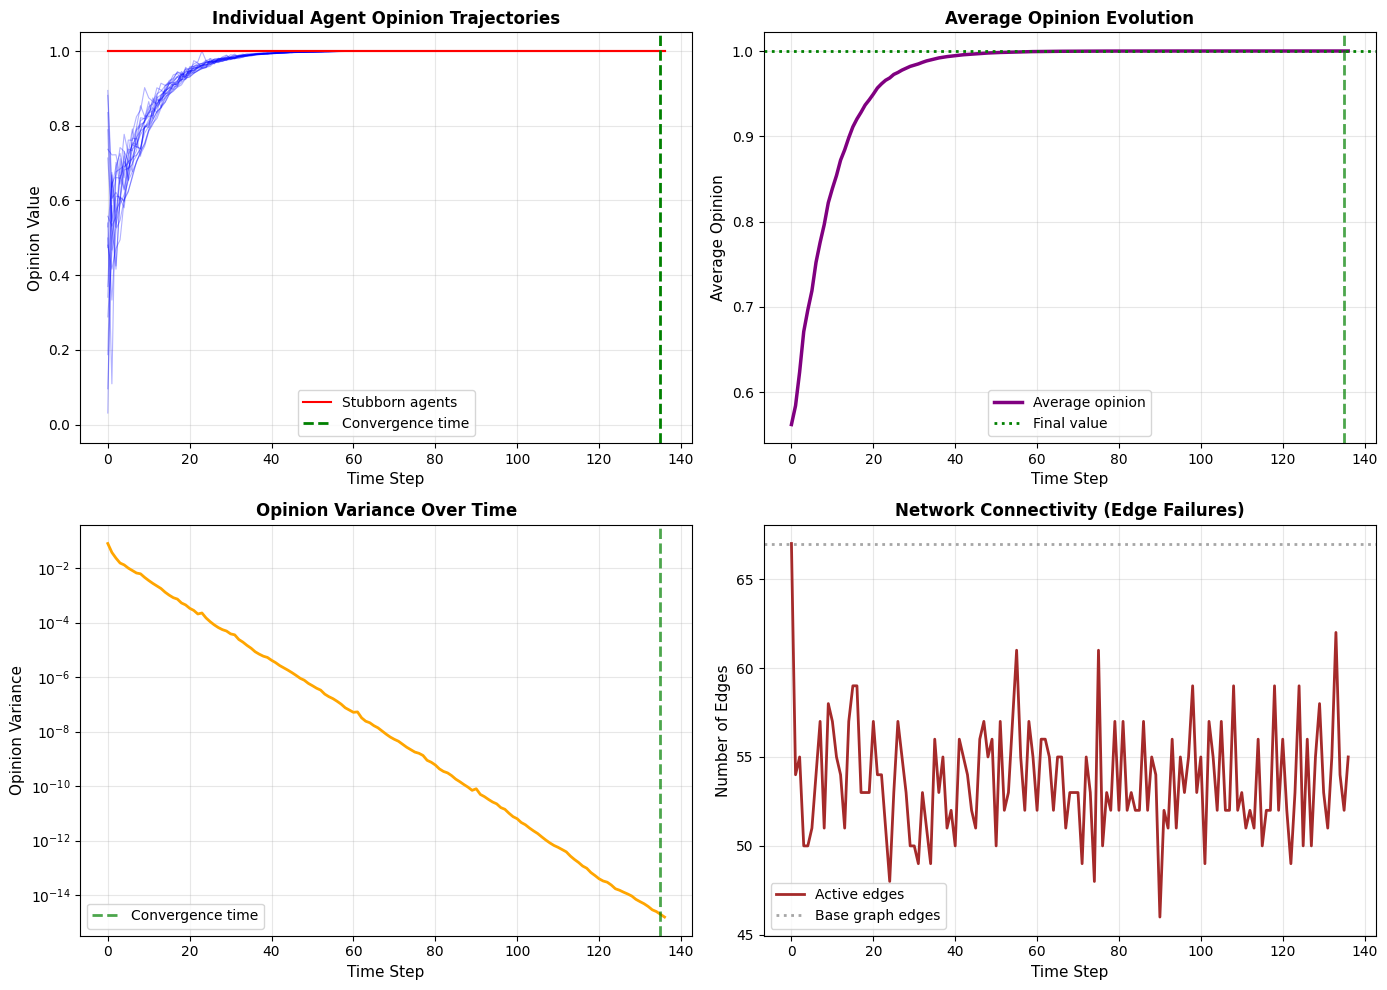


Figure: Opinion dynamics with 2 stubborn agents, 20% edge failure rate


In [ ]:
# Visualization

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Individual agent trajectories
ax = axes[0, 0]
time_steps = np.arange(len(history))

# Plot non-stubborn agents (light lines)
for i in non_stubborn_indices:
    ax.plot(time_steps, history[:, i], alpha=0.3, linewidth=0.8, color='blue')

# Plot stubborn agents (bold lines)
for i in stubborn_agents:
    ax.plot(time_steps, history[:, i], linewidth=1.5, color='red', label='Stubborn agents' if i == stubborn_agents[0] else '')

ax.axvline(x=convergence_time, color='green', linestyle='--', linewidth=2, label='Convergence time')
ax.set_xlabel('Time Step', fontsize=11)
ax.set_ylabel('Opinion Value', fontsize=11)
ax.set_title('Individual Agent Opinion Trajectories', fontsize=12, fontweight='bold')
ax.set_ylim([-0.05, 1.05])
ax.legend()
ax.grid(alpha=0.3)

# Plot 2: Average opinion over time
ax = axes[0, 1]
ax.plot(time_steps, average_opinion_history, linewidth=2.5, color='purple', label='Average opinion')
ax.axhline(y=final_avg_opinion, color='green', linestyle=':', linewidth=2, label='Final value')
ax.axvline(x=convergence_time, color='green', linestyle='--', linewidth=2, alpha=0.7)
ax.set_xlabel('Time Step', fontsize=11)
ax.set_ylabel('Average Opinion', fontsize=11)
ax.set_title('Average Opinion Evolution', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# Plot 3: Opinion variance over time
ax = axes[1, 0]
ax.plot(time_steps, opinion_variance, linewidth=2, color='orange')
ax.axvline(x=convergence_time, color='green', linestyle='--', linewidth=2, alpha=0.7, label='Convergence time')
ax.set_xlabel('Time Step', fontsize=11)
ax.set_ylabel('Opinion Variance', fontsize=11)
ax.set_title('Opinion Variance Over Time', fontsize=12, fontweight='bold')
ax.set_yscale('log')
ax.legend()
ax.grid(alpha=0.3)

# Plot 4: Network statistics
ax = axes[1, 1]
ax.plot(time_steps, edge_failure_history, linewidth=2, color='brown', label='Active edges')
ax.axhline(y=G_base.number_of_edges(), color='gray', linestyle=':', linewidth=2, alpha=0.7, label='Base graph edges')
ax.set_xlabel('Time Step', fontsize=11)
ax.set_ylabel('Number of Edges', fontsize=11)
ax.set_title('Network Connectivity (Edge Failures)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFigure: Opinion dynamics with {num_stubborn} stubborn agents, {p_fail:.0%} edge failure rate")

In [ ]:
# Detailed Analysis

# print("\n" + "=" * 50)
print("Detailed Analysis")
# print("=" * 50)

# Opinion distribution statistics
print(f"\nFinal Opinion Distribution:")
print(f"  Min: {final_opinions.min():.4f}")
print(f"  Max: {final_opinions.max():.4f}")
print(f"  Mean: {final_opinions.mean():.4f}")
print(f"  Std Dev: {final_opinions.std():.4f}")

# Agents close to truth (> 0.9)
truth_threshold = 0.9
truth_advocates = np.sum(final_opinions > truth_threshold)
print(f"\n  Agents with opinion > {truth_threshold}: {truth_advocates}/{N}")

# Polarization check
polarized = np.sum((final_opinions < 0.1) | (final_opinions > 0.9))
print(f"  Polarized agents (< 0.1 or > 0.9): {polarized}/{N}")

print(f"\nNetwork Properties:")
print(f"  Base graph average degree: {2 * G_base.number_of_edges() / N:.2f}")
print(f"  Average active edges per step: {edge_failure_history.mean():.1f}")
print(f"  Edge retention rate: {edge_failure_history.mean() / G_base.number_of_edges():.1%}")

print(f"\nConvergence Analysis:")
print(f"  Epsilon (convergence threshold): {epsilon:.2e}")
print(f"  Final opinion change rate: {np.linalg.norm(history[-1] - history[-2]):.2e}")
print(f"  Opinion variance reduction: {opinion_variance[0] / (opinion_variance[-1] + 1e-10):.1f}x")

Detailed Analysis

Final Opinion Distribution:
  Min: 1.0000
  Max: 1.0000
  Mean: 1.0000
  Std Dev: 0.0000

  Agents with opinion > 0.9: 20/20
  Polarized agents (< 0.1 or > 0.9): 20/20

Network Properties:
  Base graph average degree: 6.70
  Average active edges per step: 53.8
  Edge retention rate: 80.2%

Convergence Analysis:
  Epsilon (convergence threshold): 1.00e-06
  Final opinion change rate: 1.05e-07
  Opinion variance reduction: 798274950.1x


In [ ]:
# Optional: Parameter Sensitivity Analysis
# This cell is for analyzing how parameters affect convergence

def run_simulation(N, p, num_stubborn, p_fail, num_steps=500, epsilon=1e-6, patience=10):
    """Run a single simulation and return convergence time and final average opinion."""
    # Initialize
    G_base = nx.erdos_renyi_graph(N, p)
    x = np.random.rand(N)
    stubborn_agents = np.random.choice(N, min(num_stubborn, N), replace=False)
    x[stubborn_agents] = 1.0

    history_x = [x.copy()]

    # Simulation loop
    for step in range(num_steps):
        G_temp = G_base.copy()
        edges_to_remove = [e for e in G_temp.edges() if np.random.rand() < p_fail]
        G_temp.remove_edges_from(edges_to_remove)

        x_new = x.copy()
        for i in range(N):
            if i in stubborn_agents:
                x_new[i] = 1.0
            else:
                neighbors = list(G_temp.neighbors(i))
                if len(neighbors) > 0:
                    x_new[i] = np.mean(x[neighbors])

        x = x_new
        history_x.append(x.copy())

        # Convergence check
        if step >= patience:
            change = np.linalg.norm(history_x[-1] - history_x[-patience-1])
            if change < epsilon:
                return step, np.mean(x)

    return num_steps, np.mean(x)

# Example: Compare convergence time for different numbers of stubborn agents
results = []
for num_s in [0, 1, 2, 3, 5]:
    conv_time, final_avg = run_simulation(20, 0.3, num_s, 0.2)
    results.append((num_s, conv_time, final_avg))
    print(f"Stubborn agents: {num_s:2d} -> Convergence time: {conv_time:4d}, Final avg opinion: {final_avg:.4f}")

print("Parameter sensitivity analysis function available via run_simulation()")
#print("Uncomment the example code to perform sensitivity analysis.")

Stubborn agents:  0 -> Convergence time:   44, Final avg opinion: 0.4141
Stubborn agents:  1 -> Convergence time:  273, Final avg opinion: 1.0000
Stubborn agents:  2 -> Convergence time:  132, Final avg opinion: 1.0000
Stubborn agents:  3 -> Convergence time:  118, Final avg opinion: 1.0000
Stubborn agents:  5 -> Convergence time:   78, Final avg opinion: 1.0000
Parameter sensitivity analysis function available via run_simulation()
